# 02 · Local explanations: case studies

**Question:** *why did the model recommend this venue for this title — and what would
have to change for it to recommend the right one?*

We explain the same handful of titles with every local method so they can be compared
side by side:

| method | answers | output |
|---|---|---|
| **Exact Shapley** (ground truth) | how much does each word contribute, averaged over all ways of removing the others? | word scores |
| **LIME** | which words matter in a linear fit to random word removals? | word scores |
| **Linear SHAP** (original project) | SHAP for the linear model in TF-IDF space | n-gram scores |
| **Occlusion** | how much does the probability drop if one word is removed? | word scores |
| **Anchors** | which words are *sufficient* to keep the prediction? | if-then rule |
| **Counterfactual** | what is the smallest edit that changes the recommendation? | edit |

A note on the interpretable features: explainers operate on the distinct **lemmas of
the cleaned title**, the exact input the model sees. Stop words are removed by the
preprocessing, so they provably cannot influence the prediction and do not need to be
explained. Because titles are short (≤ 14 distinct words here), the Shapley values of
this removal game can be computed **exactly** by enumerating all subsets — this gives
us a ground truth that is usually unavailable in XAI.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice, irrelevant here

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from tcner_xai import plotting
from tcner_xai.config import RESULTS_DIR, SEED
from matplotlib.ticker import MaxNLocator

from tcner_xai.explain import (FeatureSpaceExplainer, RemovalGame, anchor_dataset_stats,
                               deletion_counterfactual, exact_shapley, explain_anchor,
                               insertion_counterfactual, lime_explain, make_anchor_explainer,
                               occlusion)
from tcner_xai.model import load_bundle

plotting.set_style()
pd.set_option("display.max_colwidth", 100)
B = load_bundle()
model, test = B.model, B.test
proba = model.clf.predict_proba(B.X_test)
pred = proba.argmax(1)
true = np.array([model.class_index(c) for c in B.y_test])

train=21,497 test=3,373 features=5,000 test accuracy=0.8615


## Choosing the cases

We revisit the titles discussed in the original report (so the corrected analysis can be
compared with it) and add the model's most *confident* mistake.

In [2]:
wanted = [
    "Efficient network generation under general preferential attachment",
    "Computer Formulation of Averaged Models for Periodically-Switched Networks",
    "An Efficient Four Layer Over-the-Cell Router",
    "Simulation and Modelling of Nonlinear Magnetics",
    "Deduplicating a places database",
]
cases = []
for w in wanted:
    hit = test.index[test["title"].str.lower().str.startswith(w.lower()[:40])]
    if len(hit):
        cases.append(int(hit[0]))
wrong = np.flatnonzero(pred != true)
most_confident_error = int(wrong[np.argmax(proba[wrong].max(1))])
if most_confident_error not in cases:
    cases.append(most_confident_error)

case_df = pd.DataFrame({
    "title": test.loc[cases, "title"].values,
    "cleaned (model input)": test.loc[cases, "clean"].values,
    "true": B.y_test[cases],
    "predicted": model.classes_[pred[cases]],
    "P(predicted)": proba[cases, pred[cases]].round(3),
}, index=cases)
display(case_df)

,title,cleaned (model input),true,predicted,P(predicted)
3,Efficient network generation under general preferential attachment.,efficient network generation general preferential attachment,WWW,INFOCOM,0.740
13,Computer Formulation of Averaged Models for Periodically-Switched Networks.,computer formulation average model periodically switch network,ISCAS,INFOCOM,0.630
20,An Efficient Four Layer Over-the-Cell Router.,efficient layer cell router,ISCAS,INFOCOM,0.645
805,Simulation and Modelling of Nonlinear Magnetics.,simulation modelling nonlinear magnetic,ISCAS,ISCAS,0.622
353,Deduplicating a places database.,deduplicate place database,WWW,VLDB,0.920
1504,Matching Titles with Cross Title Web-Search Enrichment and Community Detection.,match title cross title web search enrichment community detection,VLDB,WWW,0.923


## Four attribution methods on the same titles

All scores explain the **predicted** venue. Exact Shapley, LIME and occlusion are in
probability units; linear SHAP explains the log-odds of the one-vs-rest classifier.

In [3]:
fs = FeatureSpaceExplainer(model, B.X_train)
anchor_exp = make_anchor_explainer(model, seed=SEED)
records, explained = [], {}

for i in cases:
    clean, k, t = test.loc[i, "clean"], int(pred[i]), int(true[i])
    game = RemovalGame(model, clean)
    gt = exact_shapley(game)
    lime_attr, lime_r2, _ = lime_explain(model, clean, labels=[k], num_samples=5000, seed=SEED)
    occ = occlusion(game)
    lin = fs.explain(clean, "linear_shap")
    anchor = explain_anchor(anchor_exp, clean)
    anchor.update(anchor_dataset_stats(anchor["anchor"], test["clean"], pred, k))
    cf_true = deletion_counterfactual(model, clean, target=t) if t != k else None
    cf_any = deletion_counterfactual(model, clean)
    ins = insertion_counterfactual(model, clean, target=t) if t != k else None
    explained[i] = dict(players=game.players, gt=gt["proba"][:, k], gt_true=gt["proba"][:, t],
                        lime=lime_attr[k], occ=occ["proba"][:, k], lin=lin["logit"][:, k],
                        lin_absent=lin["top_absent"][k], absent_share=lin["absent_share"][k])
    records.append({
        "idx": i, "title": test.loc[i, "title"], "true": model.classes_[t], "pred": model.classes_[k],
        "top word (exact Shapley)": game.players[int(np.argmax(gt["proba"][:, k]))],
        "top word (LIME)": game.players[int(np.argmax(lime_attr[k]))],
        "LIME local R²": round(lime_r2, 3),
        "anchor": " AND ".join(anchor["anchor"]) or "(empty)",
        "anchor precision (alibi samples)": round(anchor["precision"], 3),
        "anchor coverage (alibi samples)": round(anchor["coverage"], 3),
        "anchor coverage (test titles)": round(anchor["data coverage"], 3),
        "anchor precision (test titles)": round(anchor["data precision"], 3),
        "remove to reach true venue": (", ".join(cf_true["removed"]) if cf_true else "—"),
        "add to reach true venue": (
            f"+ {ins['word']} (P={ins['new_proba']:.2f}{', flips' if ins['flips'] else ', no flip'})"
            if ins else "—"),
        "linear SHAP mass on absent n-grams": round(float(lin["absent_share"][k]), 3),
    })

case_table = pd.DataFrame(records).set_index("idx")
case_table.to_csv(RESULTS_DIR / "case_studies.csv")
display(case_table.T)

idx,3,13,20,805,353,1504
title,Efficient network generation under general preferential attachment.,Computer Formulation of Averaged Models for Periodically-Switched Networks.,An Efficient Four Layer Over-the-Cell Router.,Simulation and Modelling of Nonlinear Magnetics.,Deduplicating a places database.,Matching Titles with Cross Title Web-Search Enrichment and Community Detection.
true,WWW,ISCAS,ISCAS,ISCAS,WWW,VLDB
pred,INFOCOM,INFOCOM,INFOCOM,ISCAS,VLDB,WWW
top word (exact Shapley),network,network,router,nonlinear,database,web
top word (LIME),network,network,router,nonlinear,database,web
LIME local R²,0.957,0.965,0.955,0.963,0.998,0.773
anchor,network,network,router,nonlinear,database,community
anchor precision (alibi samples),1.0,1.0,1.0,1.0,1.0,1.0
anchor coverage (alibi samples),0.507,0.498,0.504,0.503,0.501,0.503
anchor coverage (test titles),0.125,0.125,0.002,0.017,0.008,0.007


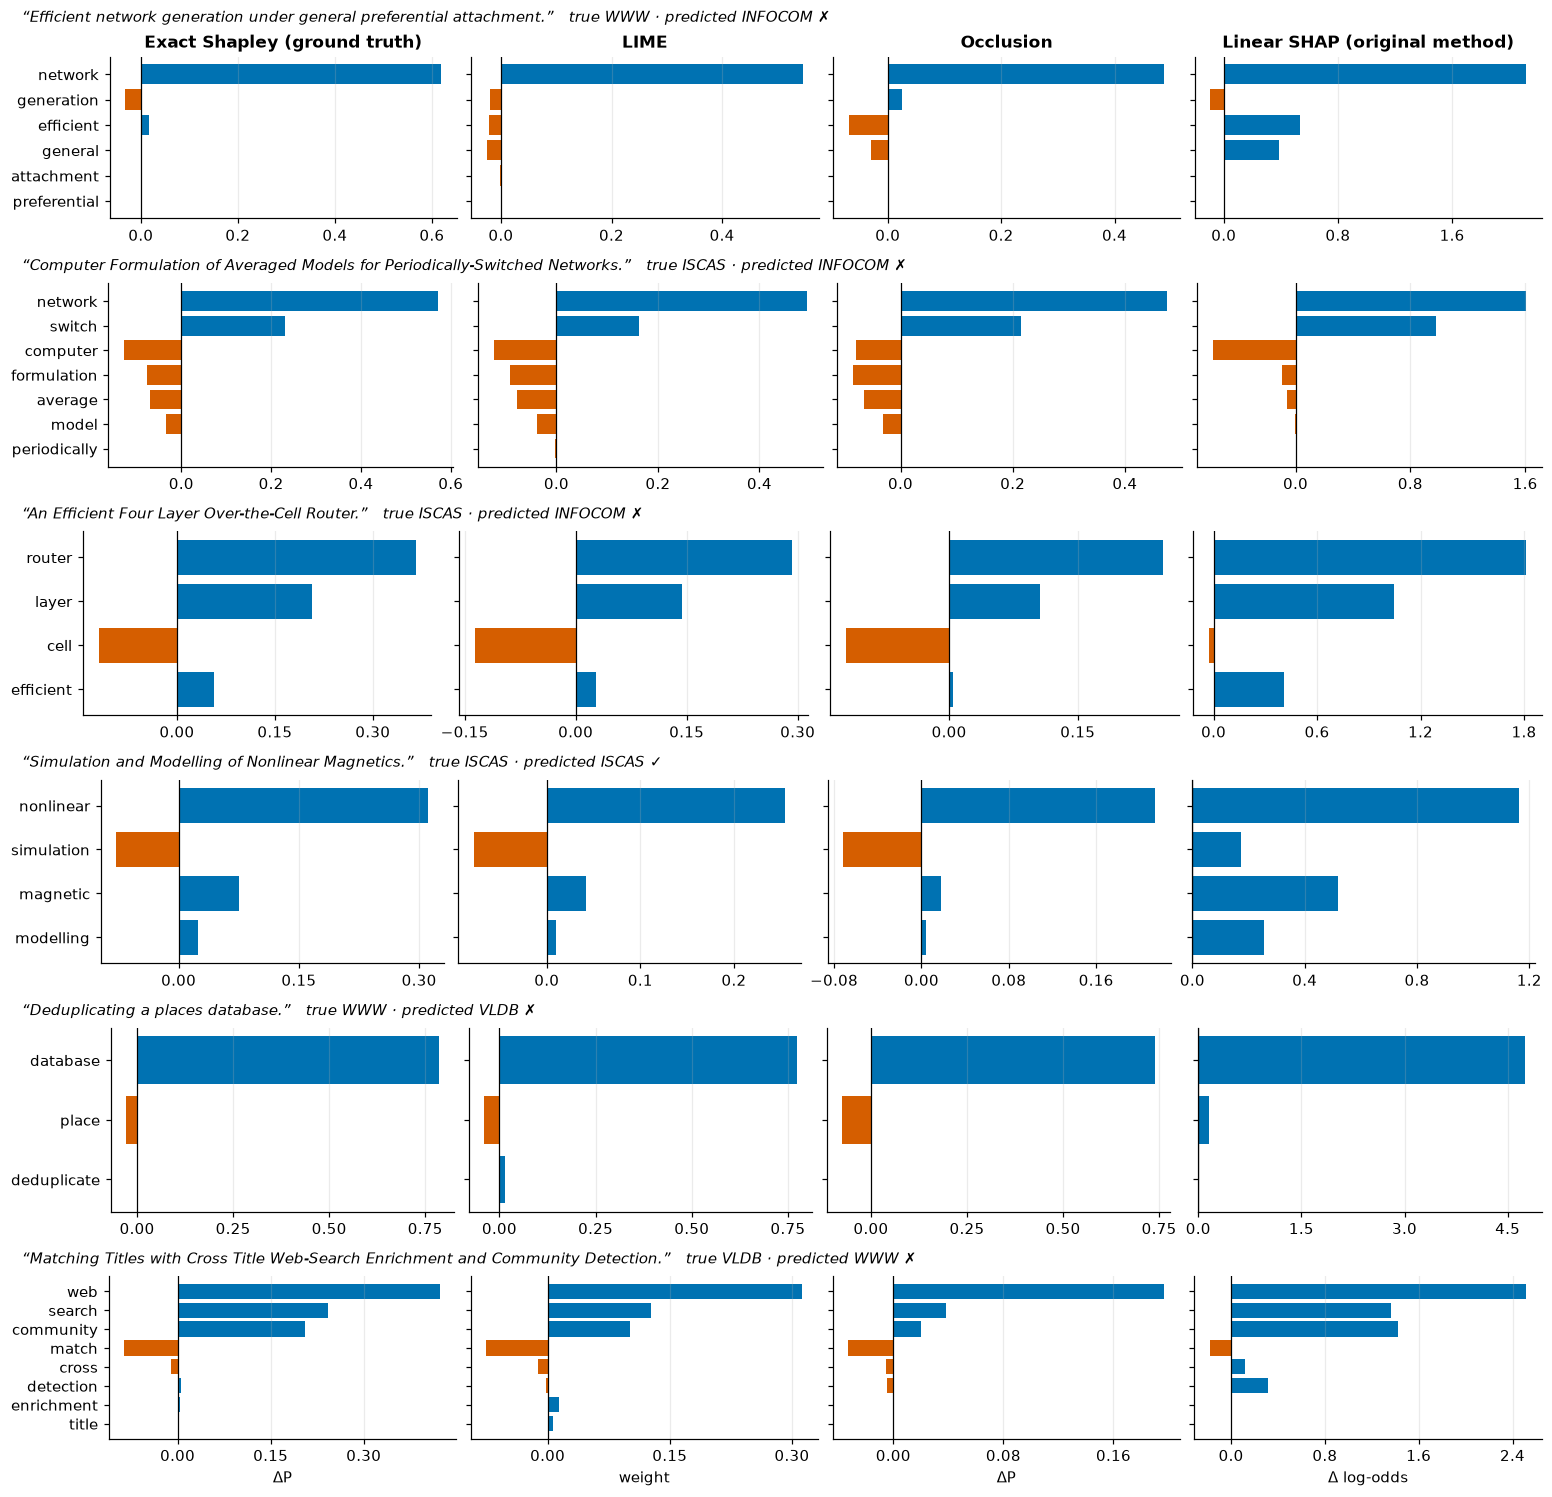

In [4]:
def caption(i):
    t = test.loc[i, "title"]
    t = t if len(t) <= 80 else t[:77] + "…"
    mark = "✓" if pred[i] == true[i] else "✗"
    return f"“{t}”   true {B.y_test[i]} · predicted {model.classes_[pred[i]]} {mark}"


panels = [("Exact Shapley (ground truth)", "gt", "ΔP"), ("LIME", "lime", "weight"),
          ("Occlusion", "occ", "ΔP"), ("Linear SHAP (original method)", "lin", "Δ log-odds")]
fig = plt.figure(figsize=(14, 2.25 * len(cases)), layout="constrained")
for r, (sf, i) in enumerate(zip(fig.subfigures(len(cases), 1), cases)):
    sf.suptitle(caption(i), x=0.01, ha="left", fontsize=10, style="italic")
    axes = sf.subplots(1, 4, sharey=True)
    for ax, (name, key, unit) in zip(axes, panels):
        plotting.attribution_bar(ax, explained[i]["players"], explained[i][key],
                                 title=name if r == 0 else "", xlabel=unit if r == len(cases) - 1 else "")
        ax.xaxis.set_major_locator(MaxNLocator(4))
plotting.save(fig, "02_local_methods_side_by_side")
plt.show()

**Reading the figure.** On short titles the four methods usually agree on the *top*
word, but they disagree on the rest of the ranking and on magnitudes. Notebook 03
measures this systematically against the exact Shapley ground truth.

## A correction to the original SHAP analysis: explanations about *missing* words

The original project used SHAP's linear explainer in TF-IDF space. For a linear model
this has the closed form φⱼ = wⱼ (xⱼ − E[xⱼ]): **every one of the 5,000 n-grams gets a
score, including the thousands that are not in the title** (xⱼ = 0). We first confirm
that our closed form matches `shap.LinearExplainer`, then measure how much of each
explanation is about absent words.

In [5]:
i0 = cases[0]
k0 = int(pred[i0])
lin_shap = shap.LinearExplainer(model.clf, shap.maskers.Independent(B.X_train, max_samples=B.X_train.shape[0]))
sv = lin_shap(B.X_test[i0]).values  # (1, d, K)
closed = model.clf.coef_[k0] * (B.X_test[i0].toarray().ravel() - np.asarray(B.X_train.mean(0)).ravel())
assert np.allclose(sv[0, :, k0], closed, atol=1e-8), "closed form differs from shap.LinearExplainer"
print("closed-form linear SHAP == shap.LinearExplainer ✓")

for i in cases[:3]:
    e = explained[i]
    print(f"\n“{test.loc[i, 'title']}” → {model.classes_[pred[i]]}")
    print(f"  share of |SHAP| on n-grams NOT in the title: {e['absent_share']:.0%}")
    print("  largest absent-word contributions:", ", ".join(f"{w} ({v:+.2f})" for w, v in e["lin_absent"]))

closed-form linear SHAP == shap.LinearExplainer ✓

“Efficient network generation under general preferential attachment.” → INFOCOM
  share of |SHAP| on n-grams NOT in the title: 42%
  largest absent-word contributions: web (+0.07), wireless (-0.06), database (+0.05), query (+0.03), cmos (+0.02)

“Computer Formulation of Averaged Models for Periodically-Switched Networks.” → INFOCOM
  share of |SHAP| on n-grams NOT in the title: 41%
  largest absent-word contributions: web (+0.07), wireless (-0.06), database (+0.05), query (+0.03), cmos (+0.02)

“An Efficient Four Layer Over-the-Cell Router.” → INFOCOM
  share of |SHAP| on n-grams NOT in the title: 43%
  largest absent-word contributions: network (-0.22), web (+0.07), wireless (-0.06), database (+0.05), query (+0.03)


The original report read force plots such as “*generation* and *web* were more associated
with the true label WWW” for *Efficient network generation under general preferential
attachment* — but **`web` does not occur in that title**. The force plot was showing
that the *absence* of `web` lowers the WWW score. With sparse text features, a large share
of a feature-space SHAP explanation is about words that are not there, which is easy to
misread as evidence present in the text. The word-level explanations above avoid this.

## Contrastive view: why venue A and not venue B?

For misclassified titles we put the exact Shapley values for the **predicted** venue next
to those for the **true** venue, and list the smallest edit that flips the decision.

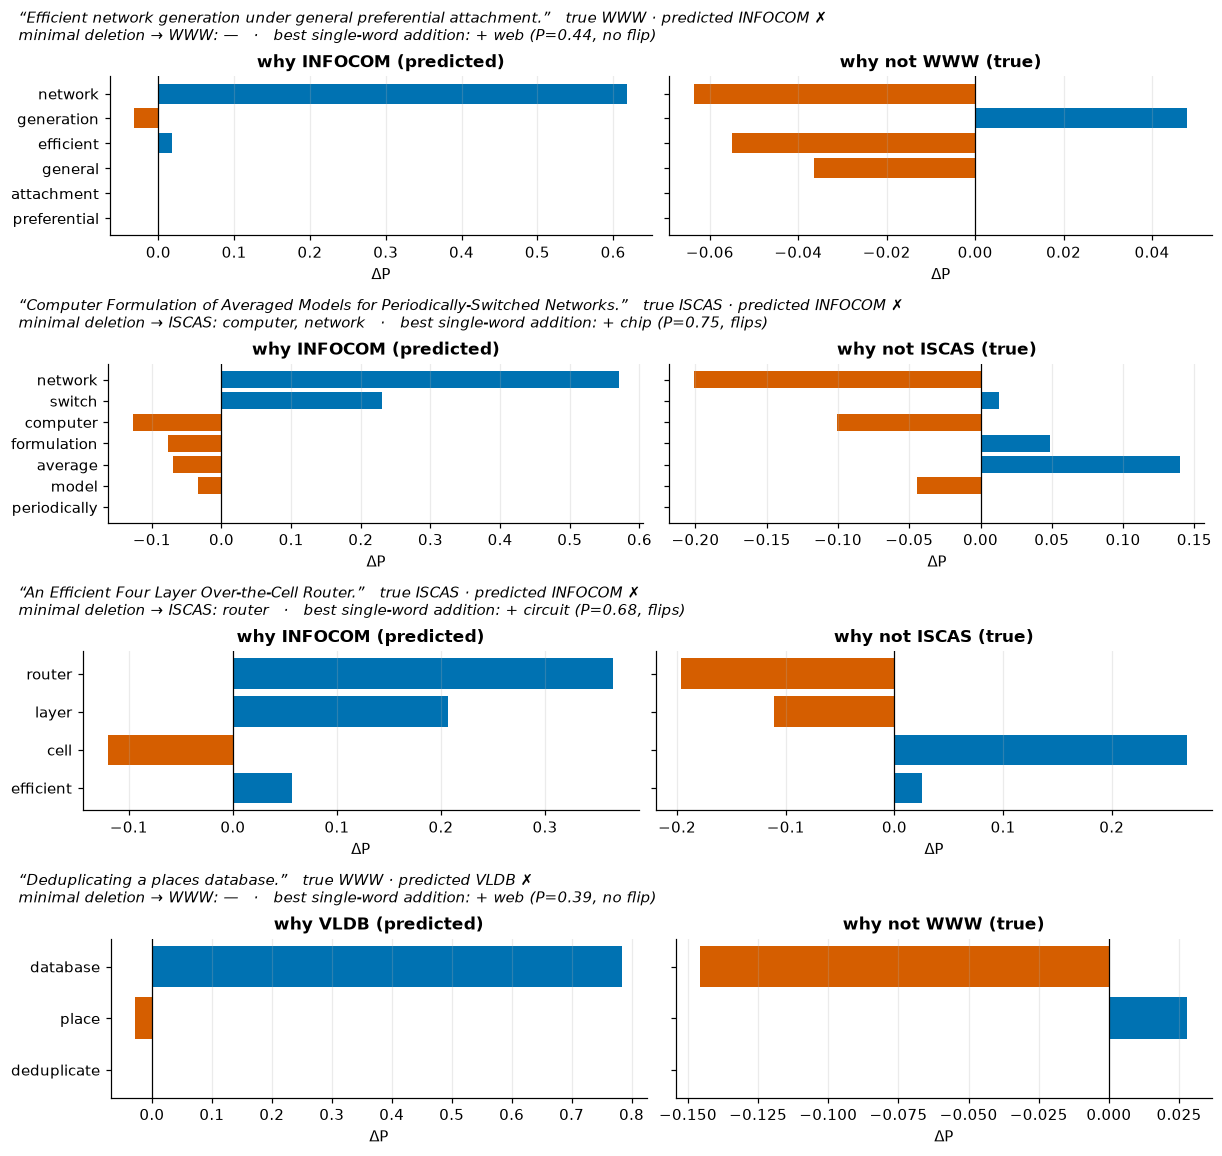

In [6]:
mis_cases = [i for i in cases if pred[i] != true[i]][:4]
fig = plt.figure(figsize=(11, 2.6 * len(mis_cases)), layout="constrained")
for sf, i in zip(fig.subfigures(len(mis_cases), 1), mis_cases):
    e, r = explained[i], case_table.loc[i]
    sf.suptitle(f"{caption(i)}\nminimal deletion → {B.y_test[i]}: {r['remove to reach true venue']}   ·   "
                f"best single-word addition: {r['add to reach true venue']}",
                x=0.01, ha="left", fontsize=9.5, style="italic")
    ax0, ax1 = sf.subplots(1, 2, sharey=True)
    plotting.attribution_bar(ax0, e["players"], e["gt"], title=f"why {model.classes_[pred[i]]} (predicted)", xlabel="ΔP")
    plotting.attribution_bar(ax1, e["players"], e["gt_true"], title=f"why not {B.y_test[i]} (true)", xlabel="ΔP")
plotting.save(fig, "02_contrastive_explanations")
plt.show()

## Take-aways

* With the preprocessing fixed, LIME, occlusion and exact Shapley point to the same
  dominant word on these titles; the methods differ in the tail of the ranking.
* **Feature-space SHAP mostly explains absent words** for sparse text, which led to a
  misinterpretation in the original report. Explanations should be computed on the
  words a user can actually see.
* **Anchors** give compact rules with a measured precision. Their *reported* coverage
  (≈ 0.5 here) is measured on alibi's own perturbation samples, not on real titles; on
  the actual test set a rule such as `network → INFOCOM` applies to only a few percent of
  titles, and its precision there is lower than the 0.95 the method promises.
* **Counterfactuals** answer the question an author actually has (*what would make this
  a SIGGRAPH paper?*) and are cheap to compute exactly for titles.